# Part 1: Understand the data and the missing values

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, roc_curve

### Cell 1: Load the data
Loads the breast cancer dataset and keeps 6 columns. Each row is one patient, each column is one measurement. `y` holds the answer (0 = malignant, 1 = benign). The table shows the first 10 patients.

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data[["mean radius", "mean texture", "mean perimeter",
               "mean area", "mean smoothness", "mean compactness"]]
y = data.target   # 0 = malignant, 1 = benign

print("Rows, columns:", X.shape)
X.head(10)

Rows, columns: (569, 6)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280
5,12.45,15.70,82.57,477.1,0.12780,0.17000
6,18.25,19.98,119.60,1040.0,0.09463,0.10900
7,13.71,20.83,90.20,577.9,0.11890,0.16450
8,13.00,21.82,87.50,519.8,0.12730,0.19320
9,12.46,24.04,83.97,475.9,0.11860,0.23960


### Cell 2: Summary of the data
Shows the minimum, maximum and average of each column, so you know what normal values look like.

In [3]:
X.describe().round(2)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


### Cell 3: Delete 20% of the values on purpose
Randomly removes 20% of the cells. The empty cells show as `NaN`, which means "missing". The original `X` stays untouched as the truth.

In [4]:
rng = np.random.default_rng(0)
Xm = X.copy()

mask = rng.random(X.shape) < 0.20      # True = this cell will be deleted
Xm = Xm.mask(mask)                     # replace those cells with NaN

Xm.head(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,NaN,NaN,0.11840,0.2776
1,20.57,17.77,132.90,1326.0,0.08474,NaN
2,19.69,NaN,130.00,NaN,0.10960,0.1599
3,11.42,20.38,NaN,NaN,0.14250,0.2839
4,20.29,14.34,135.10,1297.0,0.10030,0.1328
5,12.45,15.70,NaN,477.1,0.12780,0.1700
6,18.25,19.98,119.60,1040.0,0.09463,0.1090
7,13.71,20.83,90.20,577.9,0.11890,0.1645
8,NaN,21.82,87.50,519.8,0.12730,NaN
9,12.46,NaN,83.97,475.9,0.11860,NaN


### Cell 4: Highlight the missing values
Colours every missing cell red, so you can see exactly where the gaps are.

In [5]:
Xm.head(10).style.highlight_null(color="red")

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.990000,10.380000,nan,nan,0.118400,0.277600
1,20.570000,17.770000,132.900000,1326.000000,0.084740,nan
2,19.690000,nan,130.000000,nan,0.109600,0.159900
3,11.420000,20.380000,nan,nan,0.142500,0.283900
4,20.290000,14.340000,135.100000,1297.000000,0.100300,0.132800
5,12.450000,15.700000,nan,477.100000,0.127800,0.170000
6,18.250000,19.980000,119.600000,1040.000000,0.094630,0.109000
7,13.710000,20.830000,90.200000,577.900000,0.118900,0.164500
8,nan,21.820000,87.500000,519.800000,0.127300,nan
9,12.460000,nan,83.970000,475.900000,0.118600,nan


### Cell 5: Count the missing values
Gives the exact number and percentage of missing values in each column, plus the total.

In [6]:
missing_table = pd.DataFrame({
    "missing_count": Xm.isna().sum(),
    "missing_percent": (Xm.isna().mean() * 100).round(1)
})
print("Total cells:", Xm.size)
print("Missing cells:", Xm.isna().sum().sum())
missing_table

Total cells: 3414
Missing cells: 708


,missing_count,missing_percent
mean radius,135,23.7
mean texture,107,18.8
mean perimeter,110,19.3
mean area,123,21.6
mean smoothness,121,21.3
mean compactness,112,19.7


### Cell 6: Missing data map
A picture of the whole table. Each line is a patient, and each yellow mark is a missing value.

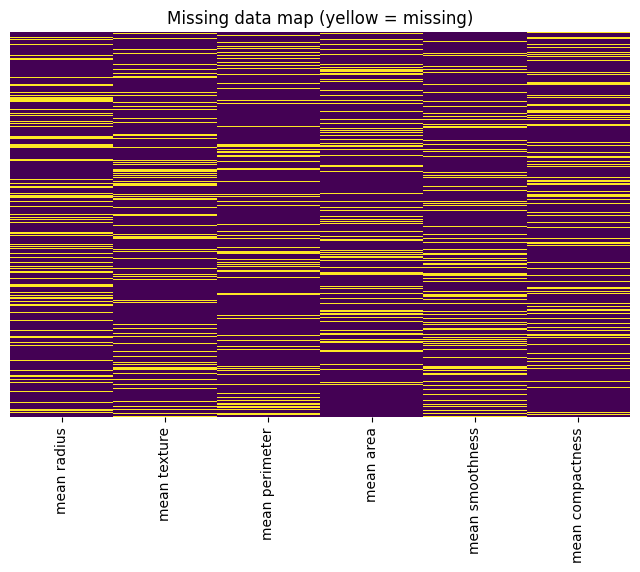

In [7]:
plt.figure(figsize=(8, 5))
sns.heatmap(Xm.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing data map (yellow = missing)")
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/missing_map.png", dpi=200, bbox_inches="tight")
plt.show()

### Cell 7: Fill the gaps and compare with the truth
Fills the missing values with the median of each column. The table puts three versions of "mean radius" side by side: the true value, the deleted version and the filled guess. This shows how far off the guess is.

In [8]:
filled = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(Xm),
    columns=Xm.columns
)

# Look at the first 5 rows where "mean radius" was deleted
rows = Xm[Xm["mean radius"].isna()].index[:5]

compare = pd.DataFrame({
    "original (truth)": X.loc[rows, "mean radius"],
    "after deleting":   Xm.loc[rows, "mean radius"],
    "after filling":    filled.loc[rows, "mean radius"].round(2)
})
compare

,original (truth),after deleting,after filling
8,13.00,NaN,13.28
11,15.78,NaN,13.28
16,14.68,NaN,13.28
18,19.81,NaN,13.28
25,17.14,NaN,13.28


### Cell 8: Does missing data hurt the model?
Trains a Random Forest on complete data and on data with 20% missing, and compares the AUC scores. AUC measures accuracy, where 1.0 is perfect. This is your first result.

In [9]:
model = RandomForestClassifier(random_state=0)

score_full   = cross_val_score(model, X, y, cv=5, scoring="roc_auc").mean()
score_filled = cross_val_score(make_pipeline(SimpleImputer(strategy="median"), model),
                               Xm, y, cv=5, scoring="roc_auc").mean()

print("AUC with complete data :", round(score_full, 3))
print("AUC with 20% missing   :", round(score_filled, 3))

AUC with complete data : 0.981
AUC with 20% missing   : 0.972


## Part 2: Compare fill methods

### Cell 9: Main graph, accuracy vs % missing
Tests three fill methods (Median, KNN, MICE) at 10% to 50% missing. The graph shows AUC dropping as more data goes missing, and the dashed line is the complete-data score. Results are saved to `results_methods.csv`. This takes 1 to 3 minutes.

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warning

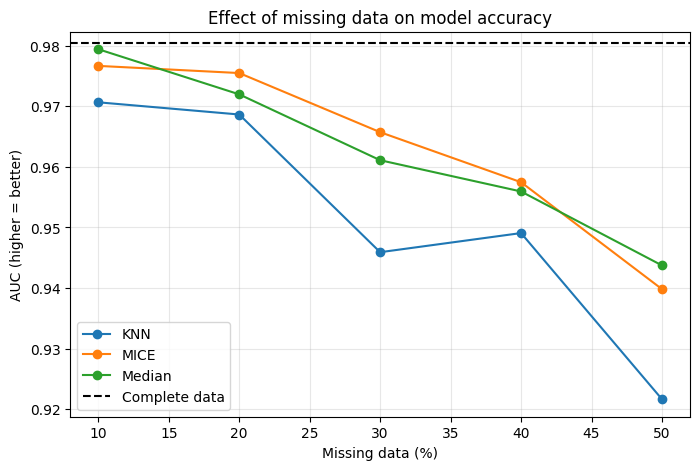

method,KNN,MICE,Median
rate,,,
10.0,0.971,0.977,0.979
20.0,0.969,0.975,0.972
30.0,0.946,0.966,0.961
40.0,0.949,0.957,0.956
50.0,0.922,0.940,0.944


In [10]:
imputers = {
    "Median": SimpleImputer(strategy="median"),
    "KNN": KNNImputer(n_neighbors=5),
    "MICE": IterativeImputer(random_state=0, max_iter=10),
}
rates = [0.1, 0.2, 0.3, 0.4, 0.5]
rows = []

for rate in rates:
    Xm = X.mask(np.random.default_rng(0).random(X.shape) < rate)
    for name, imp in imputers.items():
        pipe = make_pipeline(imp, RandomForestClassifier(n_estimators=100, random_state=0))
        auc = cross_val_score(pipe, Xm, y, cv=5, scoring="roc_auc").mean()
        rows.append({"rate": rate * 100, "method": name, "AUC": auc})

res = pd.DataFrame(rows)
res.to_csv("results_methods.csv", index=False)

# complete-data reference line
base = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=0),
                       X, y, cv=5, scoring="roc_auc").mean()

plt.figure(figsize=(8, 5))
for name, g in res.groupby("method"):
    plt.plot(g["rate"], g["AUC"], marker="o", label=name)
plt.axhline(base, color="black", linestyle="--", label="Complete data")
plt.xlabel("Missing data (%)")
plt.ylabel("AUC (higher = better)")
plt.title("Effect of missing data on model accuracy")
plt.legend()
plt.grid(alpha=0.3)
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/auc_vs_missing.png", dpi=200, bbox_inches="tight")
plt.show()
res.pivot(index="rate", columns="method", values="AUC").round(3)

### Cell 10: Does the missing pattern matter?
Compares two ways of losing data at 30%: completely random (MCAR) and bigger values more likely to disappear (MNAR). The bar chart shows whether the methods behave differently.

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


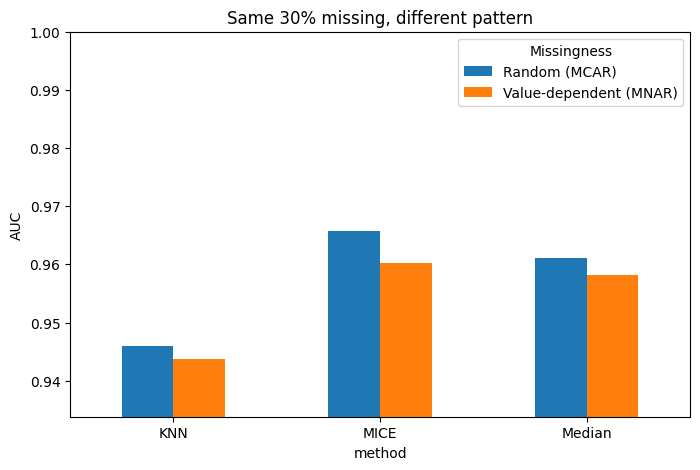

,Missingness,method,AUC
0,Random (MCAR),Median,0.961
1,Random (MCAR),KNN,0.946
2,Random (MCAR),MICE,0.966
3,Value-dependent (MNAR),Median,0.958
4,Value-dependent (MNAR),KNN,0.944
5,Value-dependent (MNAR),MICE,0.960


In [11]:
def make_mnar(X, rate, seed=0):
    rng = np.random.default_rng(seed)
    p = rate * 2 * X.rank(pct=True)          # bigger value = more likely deleted
    return X.mask(rng.random(X.shape) < p)

rate = 0.3
datasets = {
    "Random (MCAR)": X.mask(np.random.default_rng(0).random(X.shape) < rate),
    "Value-dependent (MNAR)": make_mnar(X, rate),
}

rows = []
for dname, Xm in datasets.items():
    for name, imp in imputers.items():
        pipe = make_pipeline(imp, RandomForestClassifier(n_estimators=100, random_state=0))
        auc = cross_val_score(pipe, Xm, y, cv=5, scoring="roc_auc").mean()
        rows.append({"Missingness": dname, "method": name, "AUC": auc})

res2 = pd.DataFrame(rows)
res2.pivot(index="method", columns="Missingness", values="AUC").plot(
    kind="bar", figsize=(8, 5), rot=0)
plt.ylabel("AUC")
plt.title("Same 30% missing, different pattern")
plt.ylim(res2["AUC"].min() - 0.01, 1)
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/mcar_vs_mnar.png", dpi=200, bbox_inches="tight")
plt.show()
res2.round(3)

### Cell 11: What does filling do to the data?
Plots the original "mean radius" values against the median-filled values. Median filling piles many values at one point, which distorts the real shape of the data.

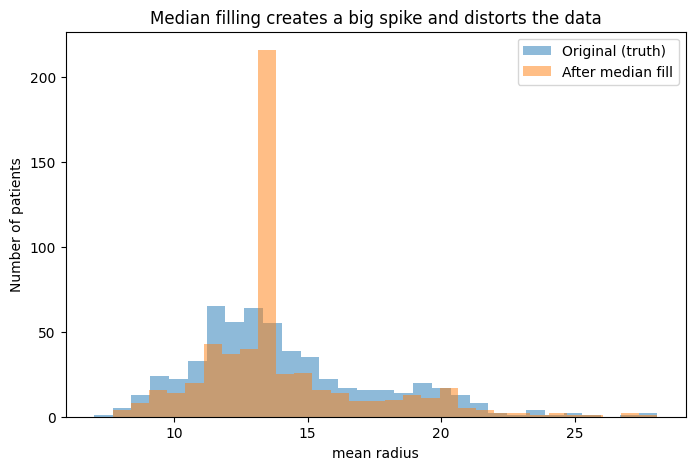

In [12]:
Xm = X.mask(np.random.default_rng(0).random(X.shape) < 0.3)
col = "mean radius"

median_fill = Xm[col].fillna(Xm[col].median())

plt.figure(figsize=(8, 5))
plt.hist(X[col], bins=30, alpha=0.5, label="Original (truth)")
plt.hist(median_fill, bins=30, alpha=0.5, label="After median fill")
plt.xlabel(col)
plt.ylabel("Number of patients")
plt.title("Median filling creates a big spike and distorts the data")
plt.legend()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/median_distortion.png", dpi=200, bbox_inches="tight")
plt.show()

## Part 3: Training vs testing and final results

### Cell 12: Split the data and train the models (run this first)
Deletes 30% of the values, then splits the patients into 80% for training (the model learns) and 20% for testing (the model is checked on unseen patients). Trains four versions: complete data, Median, KNN and MICE. Cells 13 to 15 depend on this cell.

In [13]:
# 30% of the values deleted, then split 80% train / 20% test
Xm = X.mask(np.random.default_rng(0).random(X.shape) < 0.3)
X_train, X_test, y_train, y_test = train_test_split(
    Xm, y, test_size=0.2, stratify=y, random_state=0)

# complete data (no missing) for comparison, same patients
Xc_train, Xc_test = X.loc[X_train.index], X.loc[X_test.index]

rf = RandomForestClassifier(n_estimators=100, random_state=0)
fitted = {"Complete data": rf.fit(Xc_train, y_train)}
data_test = {"Complete data": Xc_test}

for name, imp in imputers.items():
    pipe = make_pipeline(clone(imp), RandomForestClassifier(n_estimators=100, random_state=0))
    fitted[name] = pipe.fit(X_train, y_train)
    data_test[name] = X_test

print("Training patients:", len(X_train), "| Testing patients:", len(X_test))

Training patients: 455 | Testing patients: 114


### Cell 13: Training vs testing performance
Compares each model's AUC on the training patients against the testing patients. Training scores are almost always higher, because the model has seen those patients. The **test** score is the honest one.

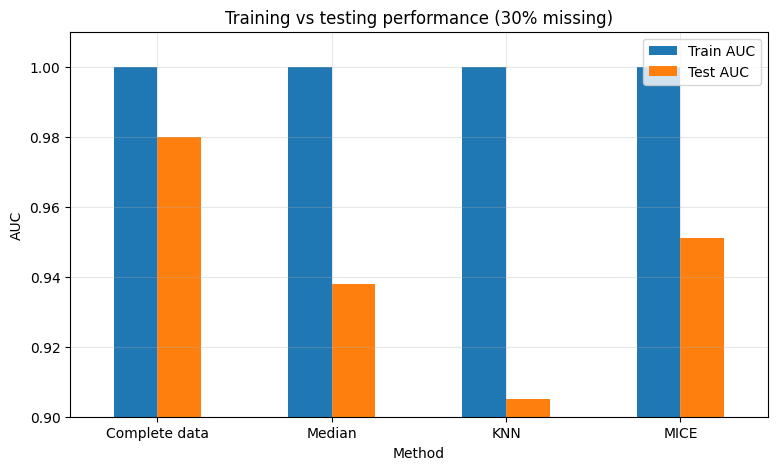

,Train AUC,Test AUC
Method,,
Complete data,1.0,0.980
Median,1.0,0.938
KNN,1.0,0.905
MICE,1.0,0.951


In [14]:
train_data = {"Complete data": Xc_train, "Median": X_train, "KNN": X_train, "MICE": X_train}
rows = []
for name, m in fitted.items():
    rows.append({"Method": name,
                 "Train AUC": roc_auc_score(y_train, m.predict_proba(train_data[name])[:, 1]),
                 "Test AUC":  roc_auc_score(y_test,  m.predict_proba(data_test[name])[:, 1])})
tt = pd.DataFrame(rows).set_index("Method")

tt.plot(kind="bar", figsize=(9, 5), rot=0)
plt.ylim(0.9, 1.01)
plt.ylabel("AUC")
plt.title("Training vs testing performance (30% missing)")
plt.grid(alpha=0.3)
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/train_vs_test.png", dpi=200, bbox_inches="tight")
plt.show()
tt.round(3)

### Cell 14: Confusion matrices (test set)
Counts the correct and wrong predictions for each model. The diagonal boxes are correct. The off-diagonal boxes are mistakes, and the most serious is a malignant patient predicted as benign.

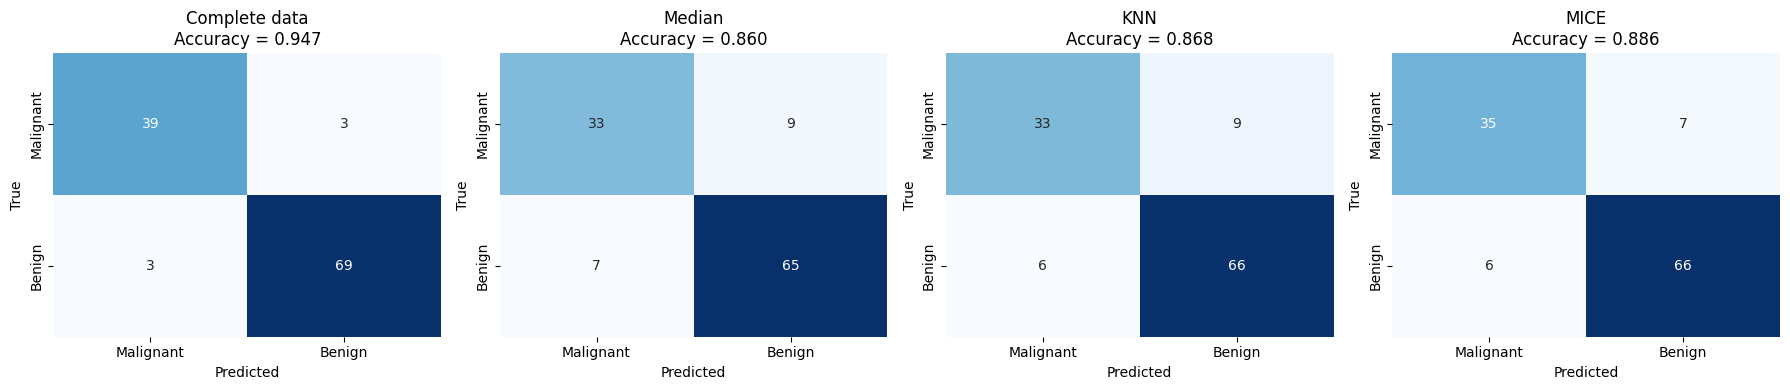

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, fitted.items()):
    pred = m.predict(data_test[name])
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, pred):.3f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/confusion.png", dpi=200, bbox_inches="tight")
plt.show()

### Cell 15: ROC curves (test set)
Plots how well each model separates malignant from benign patients. The closer a curve is to the top-left corner, the better the model. The AUC value is shown in the legend.

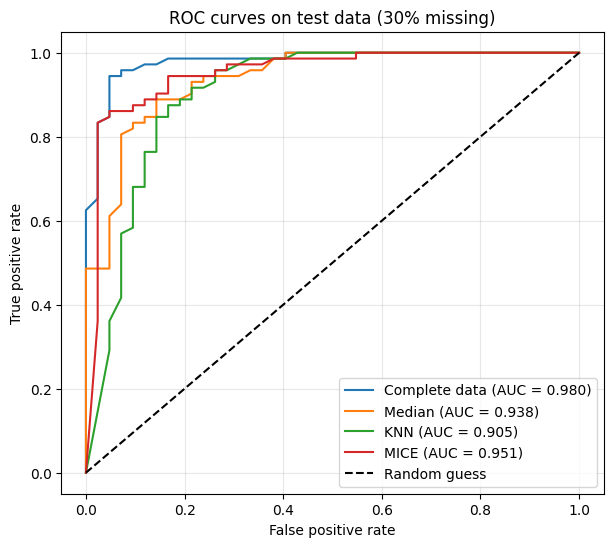

In [16]:
plt.figure(figsize=(7, 6))
for name, m in fitted.items():
    p = m.predict_proba(data_test[name])[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on test data (30% missing)")
plt.legend(); plt.grid(alpha=0.3)
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

### Cell 16: Final results summary
Gathers all results from Cell 9 into one bar chart and one table: every method at every missing level, plus the average AUC per method. This is your final results slide. It needs Cell 9 to have run in the same session.

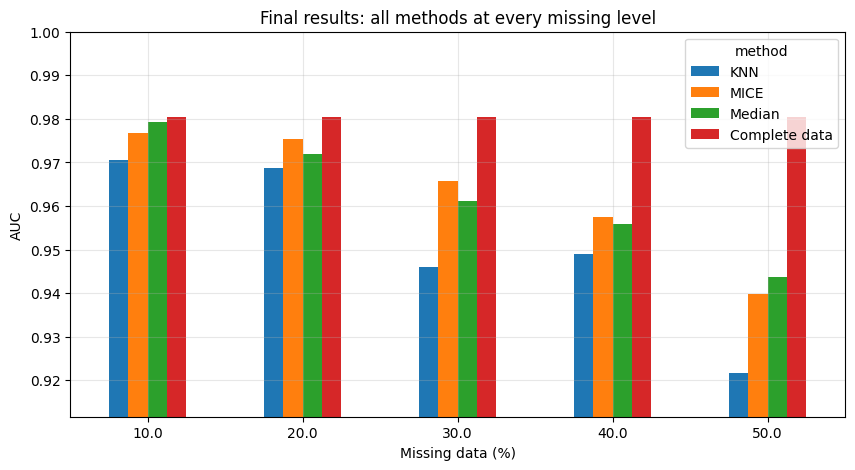

Average AUC per method (across all missing levels):
method
KNN              0.951
MICE             0.963
Median           0.962
Complete data    0.981
dtype: float64


method,KNN,MICE,Median,Complete data
rate,,,,
10.0,0.971,0.977,0.979,0.981
20.0,0.969,0.975,0.972,0.981
30.0,0.946,0.966,0.961,0.981
40.0,0.949,0.957,0.956,0.981
50.0,0.922,0.940,0.944,0.981


<Figure size 640x480 with 0 Axes>

In [17]:
final = res.pivot(index="rate", columns="method", values="AUC")
final["Complete data"] = base

ax = final.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_xlabel("Missing data (%)")
ax.set_ylabel("AUC")
ax.set_ylim(final.min().min() - 0.01, 1)
ax.set_title("Final results: all methods at every missing level")
ax.grid(alpha=0.3)
plt.show()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/final_results.png", dpi=200, bbox_inches="tight")
print("Average AUC per method (across all missing levels):")
print(final.mean().round(3))
final.round(3)

In [18]:
print("Complete-data AUC:", round(base, 3))
print("\nAUC by method and % missing (Cell 9):")
print(res.pivot(index="rate", columns="method", values="AUC").round(3))
print("\nAverage AUC per method:")
print(res.groupby("method")["AUC"].mean().round(3))
print("\nTraining vs testing (Cell 13):")
print(tt.round(3))
print("\nMCAR vs MNAR at 30% (Cell 10):")
print(res2.pivot(index="method", columns="Missingness", values="AUC").round(3))

Complete-data AUC: 0.981

AUC by method and % missing (Cell 9):
method    KNN   MICE  Median
rate                        
10.0    0.971  0.977   0.979
20.0    0.969  0.975   0.972
30.0    0.946  0.966   0.961
40.0    0.949  0.957   0.956
50.0    0.922  0.940   0.944

Average AUC per method:
method
KNN       0.951
MICE      0.963
Median    0.962
Name: AUC, dtype: float64

Training vs testing (Cell 13):
               Train AUC  Test AUC
Method                            
Complete data        1.0     0.980
Median               1.0     0.938
KNN                  1.0     0.905
MICE                 1.0     0.951

MCAR vs MNAR at 30% (Cell 10):
Missingness  Random (MCAR)  Value-dependent (MNAR)
method                                            
KNN                  0.946                   0.944
MICE                 0.966                   0.960
Median               0.961                   0.958


In [19]:
!zip -r figures.zip figures

  adding: figures/ (stored 0%)
  adding: figures/confusion.png (deflated 23%)
  adding: figures/missing_map.png (deflated 20%)
  adding: figures/mcar_vs_mnar.png (deflated 22%)
  adding: figures/median_distortion.png (deflated 20%)
  adding: figures/final_results.png (deflated 96%)
  adding: figures/roc_curves.png (deflated 12%)
  adding: figures/auc_vs_missing.png (deflated 8%)
  adding: figures/train_vs_test.png (deflated 23%)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')